# 02: Exploratory data analysis

Dataset: `data/hdi_wdi_2023.csv` — one row per country (193 countries), reference year 2023.
9 numerical WDI indicators, 2 categorical columns (`region`, `DominantSector`), and the target `hdi_class`
(0 = Low, 1 = Medium/High, 2 = Very High). Column meanings are in `data/data_dictionary.md`.

EDA describes the data with tables and plots; it doesn't build models. A short observation is written
under every output below.

## 1. Inspect the dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/hdi_wdi_2023.csv")
CLASS_NAMES = {0: "Low", 1: "Medium/High", 2: "Very High"}
df["class_name"] = df["hdi_class"].map(CLASS_NAMES)
ORDER = ["Low", "Medium/High", "Very High"]
NUM = ["gdp_growth", "inflation", "unemployment", "infant_mortality", "electricity_access",
       "internet_users", "agriculture_gdp", "industry_gdp", "trade_gdp"]
CAT = ["region", "DominantSector"]

print("countries:", len(df))
df[NUM + CAT].dtypes

countries: 193


gdp_growth            float64
inflation             float64
unemployment          float64
infant_mortality      float64
electricity_access    float64
internet_users        float64
agriculture_gdp       float64
industry_gdp          float64
trade_gdp             float64
region                 object
DominantSector         object
dtype: object

In [2]:
df[NUM].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
gdp_growth,189.0,2.94,4.62,-29.43,1.13,3.13,4.94,33.80
inflation,178.0,11.48,23.84,-4.64,3.61,5.87,9.33,221.34
unemployment,179.0,6.89,5.71,0.13,3.15,5.18,8.50,34.61
infant_mortality,191.0,19.35,17.38,1.30,5.10,13.20,30.05,71.90
electricity_access,193.0,87.05,23.22,5.40,85.30,100.00,100.00,100.00
internet_users,182.0,71.15,25.32,7.17,58.23,81.26,90.84,100.00
agriculture_gdp,186.0,10.25,10.25,0.02,2.35,6.65,16.79,43.99
industry_gdp,186.0,26.07,11.95,2.09,18.12,24.53,31.56,78.90
trade_gdp,170.0,94.28,61.06,2.47,51.26,82.11,116.39,402.57


class_name
Low            26
Medium/High    93
Very High      74
Name: count, dtype: int64
class_name
Low            13.5
Medium/High    48.2
Very High      38.3
Name: count, dtype: float64


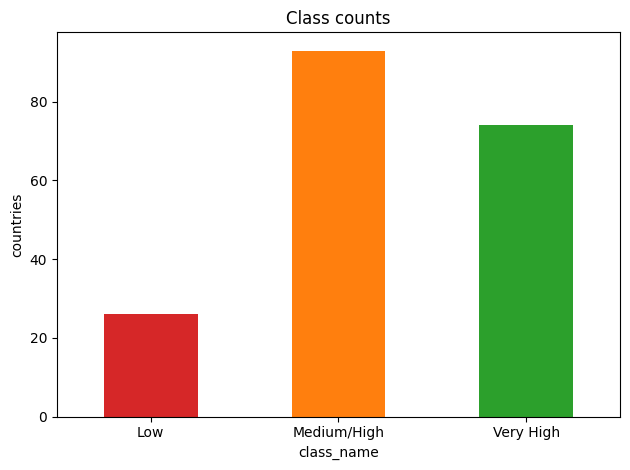

In [3]:
counts = df["class_name"].value_counts().reindex(ORDER)
props = (counts / len(df) * 100).round(1)
print(counts)
print(props)

counts.plot.bar(rot=0, color=["tab:red", "tab:orange", "tab:green"], title="Class counts")
plt.ylabel("countries")
plt.tight_layout()
plt.savefig("../figures/class_counts.png", dpi=150)
plt.show()

**Observation:** 193 countries, 9 numerical features, 2 categorical features, all correctly typed as
`float64`/`object`. The three classes are imbalanced — Low is the smallest group and Medium/High is the
largest — so later modelling needs a stratified split and macro F1 rather than plain accuracy.

In [4]:
missing_summary = pd.DataFrame({
    "Missing Count": df[NUM + CAT].isnull().sum(),
    "Percentage (%)": (df[NUM + CAT].isnull().sum() / len(df) * 100).round(1)
}).sort_values(by="Percentage (%)", ascending=False)

print(missing_summary[missing_summary["Missing Count"] > 0])

                  Missing Count  Percentage (%)
trade_gdp                    23            11.9
inflation                    15             7.8
unemployment                 14             7.3
internet_users               11             5.7
DominantSector                7             3.6
industry_gdp                  7             3.6
agriculture_gdp               7             3.6
gdp_growth                    4             2.1
infant_mortality              2             1.0


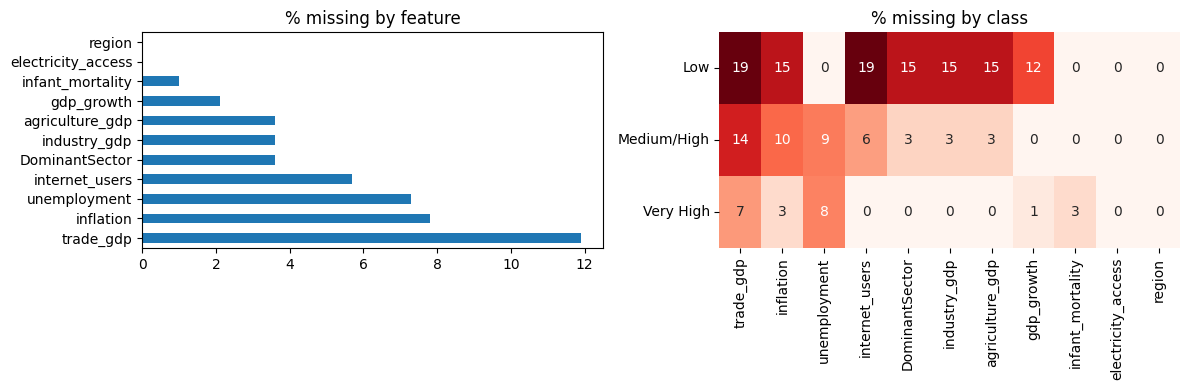

In [5]:
# Missingness by class: fraction missing per feature, computed one class at a time
# with boolean masking (same technique as 09_pandas.ipynb).
rows = {}
for k in ORDER:
    sub = df[df["class_name"] == k]
    rows[k] = (sub[NUM + CAT].isnull().sum() / len(sub) * 100).round(1)
by_class = pd.DataFrame(rows).T.reindex(ORDER)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
missing_summary["Percentage (%)"].plot.barh(ax=ax[0], title="% missing by feature")
sns.heatmap(by_class[missing_summary.index], annot=True, fmt=".0f", cmap="Reds", cbar=False, ax=ax[1])
ax[1].set_yticklabels(ORDER, rotation=0)
ax[1].set_title("% missing by class")
plt.tight_layout()
plt.savefig("../figures/missingness.png", dpi=150)
plt.show()

**Observation:** `trade_gdp` is the most-missing feature (11.9%), followed by `inflation` (7.8%) and
`unemployment` (7.3%); `electricity_access` and `region` are complete. By class, most features are missing
far more often for Low-HDI countries: for example `internet_users` and `trade_gdp` are 19% missing in the Low
class but 0% and 7% in the Very High class. `unemployment` is the exception (0% missing in Low, about 8% in the
other two classes). So missingness is not completely random; it is related to development class
(examined further in Section 6).

## 2. Distributions, skewness and extreme values

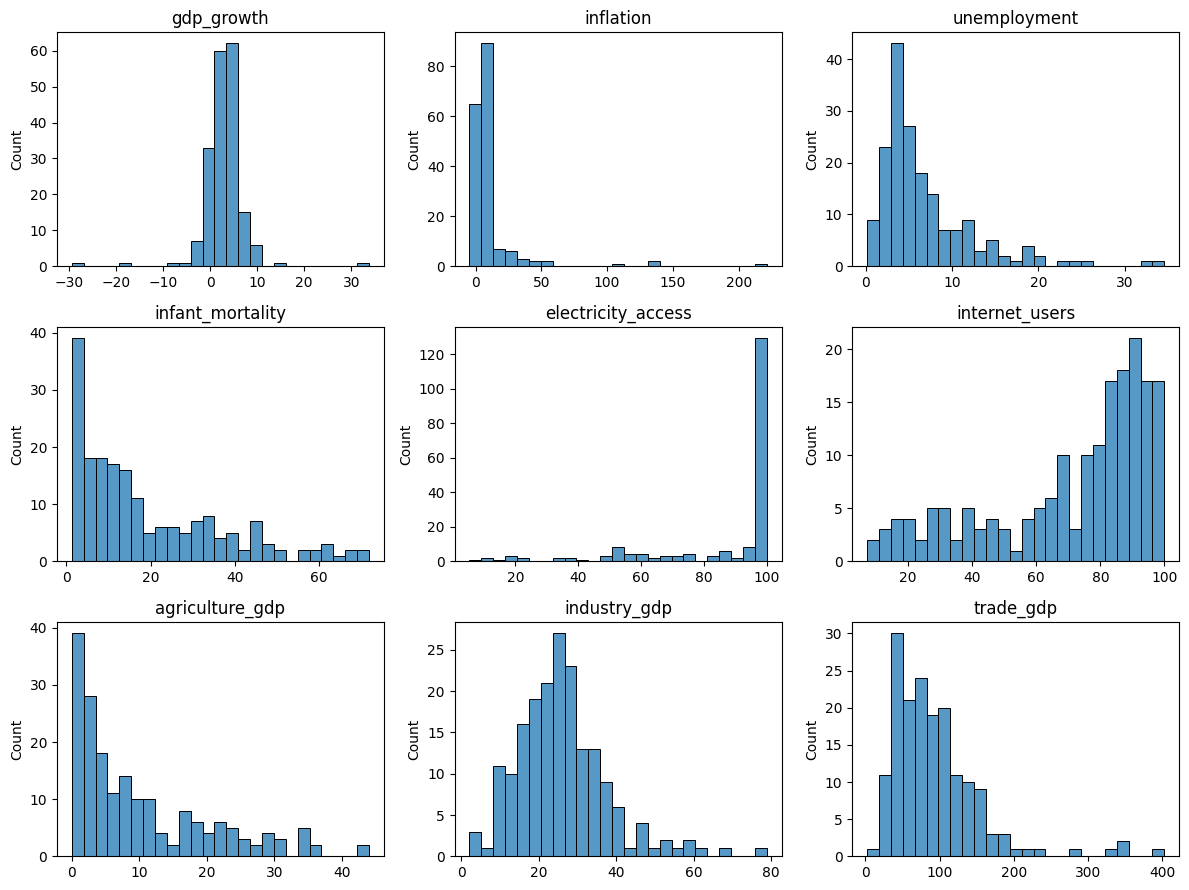

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, c in zip(axes.ravel(), NUM):
    sns.histplot(df[c].dropna(), bins=25, ax=ax)
    ax.set_title(c)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("../figures/histograms.png", dpi=150)
plt.show()

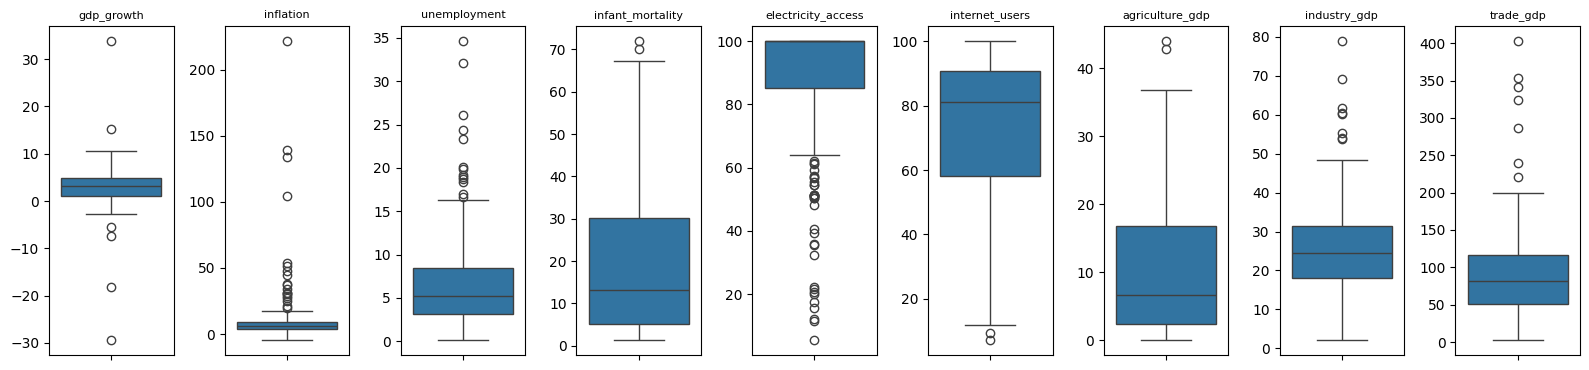

In [7]:
fig, axes = plt.subplots(1, 9, figsize=(16, 3.8))
for ax, c in zip(axes, NUM):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c, fontsize=8)
    ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../figures/boxplots.png", dpi=150)
plt.show()

In [8]:
# Skewness check, as in the EDA notes: mean > median -> long right tail, mean < median -> long left tail.
# Extreme values are counted with the 1.5 x IQR rule (detect_outliers_iqr in 17_EDA.ipynb).
rows = []
for c in NUM:
    Q1 = df[c].quantile(0.25)
    Q3 = df[c].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    n_outliers = ((df[c] < lower_bound) | (df[c] > upper_bound)).sum()
    rows.append({"mean": df[c].mean(), "median": df[c].median(),
                 "mean - median": df[c].mean() - df[c].median(),
                 "IQR outliers": n_outliers, "lower bound": lower_bound,
                 "upper bound": upper_bound, "min": df[c].min(), "max": df[c].max()})

skew_table = pd.DataFrame(rows, index=NUM).round(2)
skew_table

,mean,median,mean - median,IQR outliers,lower bound,upper bound,min,max
gdp_growth,2.94,3.13,-0.19,6,-4.59,10.66,-29.43,33.80
inflation,11.48,5.87,5.61,19,-4.98,17.91,-4.64,221.34
unemployment,6.89,5.18,1.70,13,-4.87,16.52,0.13,34.61
infant_mortality,19.35,13.20,6.15,2,-32.33,67.48,1.30,71.90
electricity_access,87.05,100.00,-12.95,33,63.25,122.05,5.40,100.00
internet_users,71.15,81.26,-10.11,2,9.30,139.77,7.17,100.00
agriculture_gdp,10.25,6.65,3.60,2,-19.30,38.44,0.02,43.99
industry_gdp,26.07,24.53,1.54,8,-2.02,51.71,2.09,78.90
trade_gdp,94.28,82.11,12.17,7,-46.43,214.09,2.47,402.57


In [9]:
# Extreme values: the countries with the highest values of the most spread-out features,
# found with sort_values() (as used in Section 1).
for c in ["inflation", "trade_gdp", "gdp_growth", "unemployment"]:
    top3 = df.sort_values(c, ascending=False)[["country", c]].head(3)
    print(c, "highest:")
    print(top3.to_string(index=False))
    print()

print("gdp_growth lowest:")
print(df.sort_values("gdp_growth")[["country", "gdp_growth"]].head(3).to_string(index=False))
print()

pct =["unemployment", "electricity_access", "internet_users", "agriculture_gdp", "industry_gdp"]
out_of_range = ((df[pct] < 0) | (df[pct] > 100)).sum().sum()
print("percentages outside 0-100:", int(out_of_range))

inflation highest:
  country  inflation
  Lebanon 221.341644
    Sudan 138.808460
Argentina 133.488936

trade_gdp highest:
               country  trade_gdp
            Luxembourg 402.566968
Hong Kong, China (SAR) 353.194609
            San Marino 340.983400

gdp_growth highest:
country  gdp_growth
 Guyana   33.795011
  Samoa   15.233606
  Malta   10.634056

unemployment highest:
              country  unemployment
Eswatini (Kingdom of)        34.610
         South Africa        32.098
             Djibouti        26.074

gdp_growth lowest:
          country  gdp_growth
            Sudan  -29.433272
      Timor-Leste  -18.135905
Equatorial Guinea   -7.425055

percentages outside 0-100: 0


**Observation:** Mean vs median gives the direction of skew. `inflation`, `trade_gdp`, `infant_mortality`,
`agriculture_gdp` and `unemployment` have mean > median (long right tail); `electricity_access` and
`internet_users` have mean < median (most countries are bunched near 100%, with a tail of low-access countries).
The most extreme values are in `inflation` (19 IQR outliers; Lebanon 221%, Sudan 139%, Argentina 133%, against an
upper bound of about 18%) and `trade_gdp` (Luxembourg 403%, Hong Kong 353%, San Marino 341% of GDP).
`gdp_growth` has extremes on both sides (Guyana +33.8%, Sudan −29.4%).

These are real economies (hyperinflation, small trading hubs, an oil boom, conflict), and no percentage column falls
outside 0–100, so nothing is removed as an error. Because `inflation` and `trade_gdp` are unbounded and span very
different scales, they are log-transformed in the modelling notebook (a sign-preserving log, since inflation can be
negative). The 33 low-side outliers in `electricity_access` are genuine low-access countries, which is exactly the
information that identifies the Low class, so they are kept and not transformed.

## 3. Indicators across the three classes

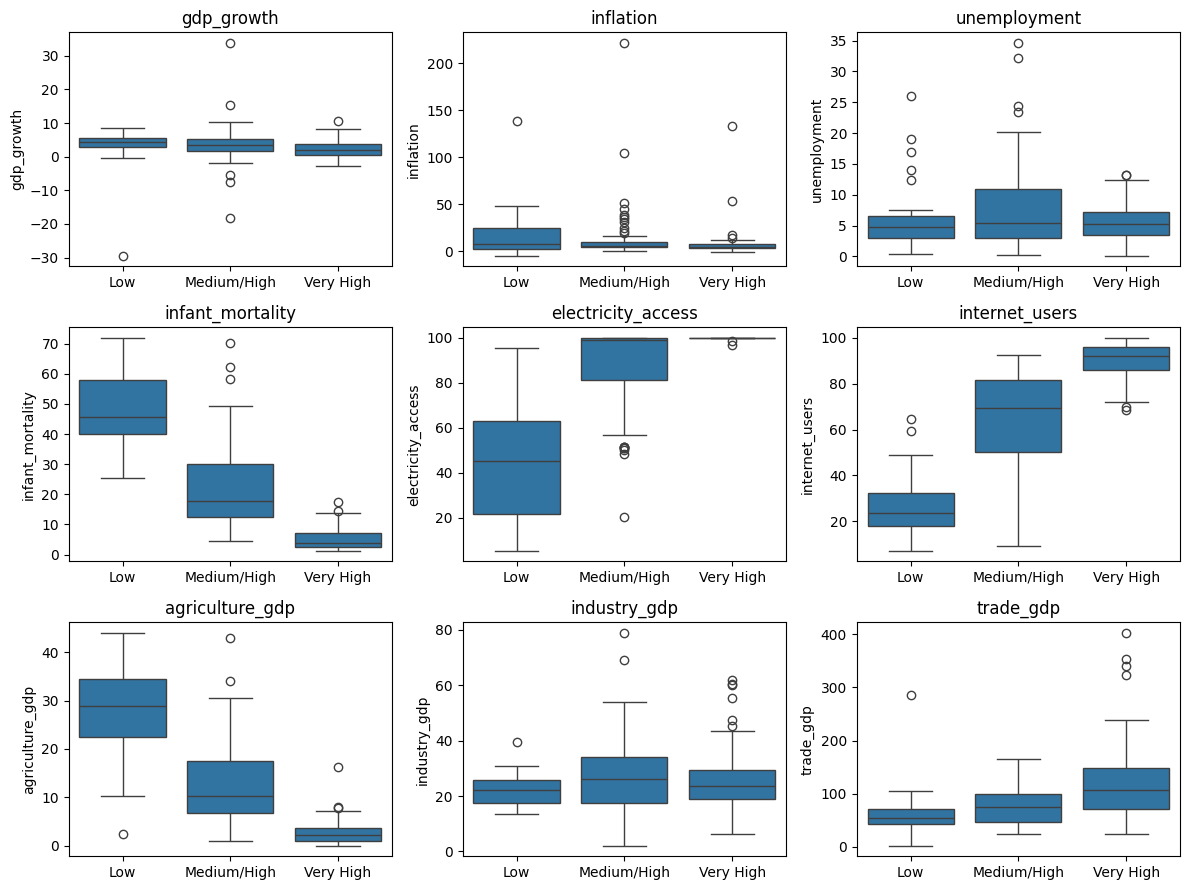

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, c in zip(axes.ravel(), NUM):
    sns.boxplot(data=df, x="class_name", y=c, order=ORDER, ax=ax)
    ax.set_xlabel("")
    ax.set_title(c)
plt.tight_layout()
plt.savefig("../figures/features_by_class.png", dpi=150)
plt.show()

In [11]:
df.groupby("class_name")[NUM].median().reindex(ORDER).T.round(1)

class_name,Low,Medium/High,Very High
gdp_growth,4.3,3.5,2.0
inflation,7.5,6.0,5.0
unemployment,4.7,5.4,5.2
infant_mortality,45.7,17.7,4.0
electricity_access,45.4,99.3,100.0
internet_users,23.7,69.6,92.2
agriculture_gdp,29.0,10.3,2.1
industry_gdp,22.2,26.3,23.7
trade_gdp,55.3,75.0,107.3


**Observation:** `infant_mortality` (median 45.7 → 17.7 → 4.0 per 1,000), `internet_users` (23.7 → 69.6 → 92.2%),
`electricity_access` (45.4 → 99.3 → 100%) and `agriculture_gdp` (29.0 → 10.3 → 2.1% of GDP) change strongly and
steadily from Low to Very High, with little overlap between the Low and Very High boxes. `trade_gdp` also rises
(55 → 107% of GDP) but with a wide spread. `unemployment` and `industry_gdp` barely differ across classes, and
`gdp_growth` is slightly higher in Low countries (median 4.3% vs 2.0%) with heavy overlap. These are associations
only: they do not show that any indicator causes a country's HDI class.

## 4. Correlations

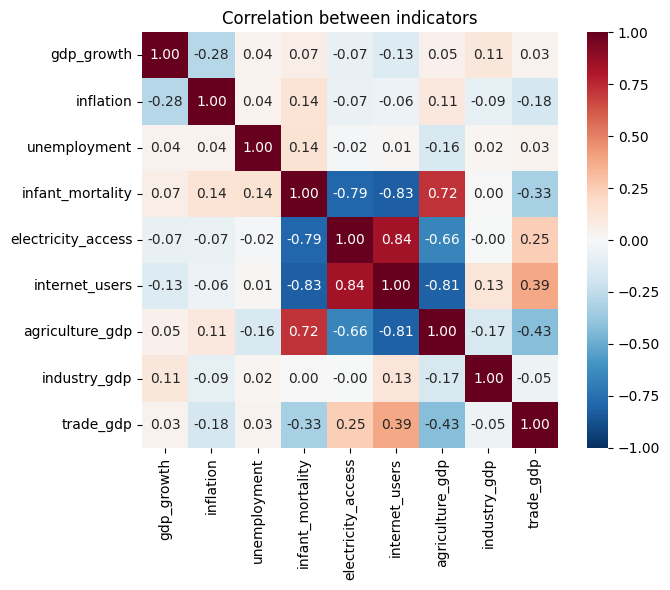

In [12]:
corr = df[NUM].corr(method="pearson")
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Correlation between indicators")
plt.tight_layout()
plt.savefig("../figures/correlation.png", dpi=150)
plt.show()

In [13]:
# Strongly correlated pairs (|r| >= 0.5), read off the matrix above with a plain loop
# over column pairs.
cols = list(corr.columns)
strong_pairs = []
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr.iloc[i, j]
        if abs(r) >= 0.5:
            strong_pairs.append((cols[i], cols[j], round(r, 2)))

strong_pairs.sort(key=lambda t: abs(t[2]), reverse=True)
for a, b, r in strong_pairs:
    print(f"{a} vs {b}: r = {r}")

electricity_access vs internet_users: r = 0.84
infant_mortality vs internet_users: r = -0.83
internet_users vs agriculture_gdp: r = -0.81
infant_mortality vs electricity_access: r = -0.79
infant_mortality vs agriculture_gdp: r = 0.72
electricity_access vs agriculture_gdp: r = -0.66


**Observation:** Six pairs have |r| ≥ 0.5, all within four indicators: `electricity_access` and `internet_users`
(r = 0.84), `infant_mortality` vs `internet_users` (−0.83), `internet_users` vs `agriculture_gdp` (−0.81),
`infant_mortality` vs `electricity_access` (−0.79), `infant_mortality` vs `agriculture_gdp` (0.72) and
`electricity_access` vs `agriculture_gdp` (−0.66). These four partly measure the same underlying "level of
development", so they are potentially redundant: logistic-regression coefficients on them should be read with
caution, and PCA should be able to compress them. The macroeconomic indicators (growth, inflation, unemployment,
trade, industry) are only weakly correlated with this block and with each other. Pearson's r measures linear
association only, not causation.

## 5. Categorical variables

In [14]:
for c in CAT:
    print(df[c].value_counts(dropna=False))
    print()

region
Europe & Central Asia         51
Sub-Saharan Africa            48
Latin America & Caribbean     33
East Asia & Pacific           30
Middle East & North Africa    23
South Asia                     6
North America                  2
Name: count, dtype: int64

DominantSector
Services       176
Industry         8
NaN              7
Agriculture      2
Name: count, dtype: int64



class_name                  Low  Medium/High  Very High
region                                                 
East Asia & Pacific           0           22          8
Europe & Central Asia         0            7         44
Latin America & Caribbean     0           23         10
Middle East & North Africa    4           11          8
North America                 0            0          2
South Asia                    0            6          0
Sub-Saharan Africa           22           24          2


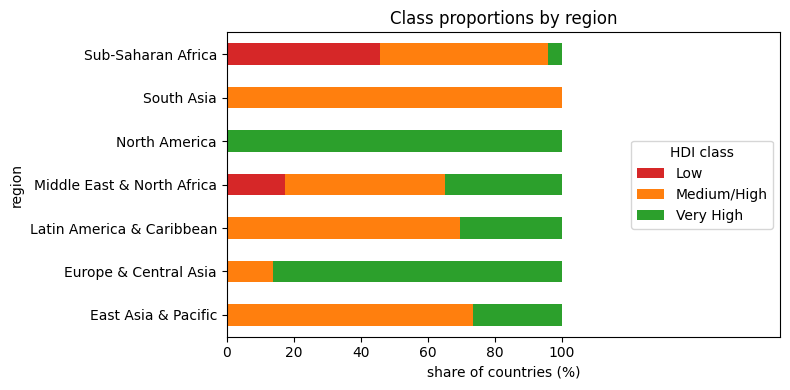

In [15]:
ct = pd.crosstab(df["region"], df["class_name"])[ORDER]
print(ct)

prop = pd.crosstab(df["region"], df["class_name"], normalize="index")[ORDER] * 100
prop.plot.barh(stacked=True, figsize=(8, 4), color=["tab:red", "tab:orange", "tab:green"])
plt.xlabel("share of countries (%)")
plt.xlim(0, 165)                                   # leave room on the right for the legend
plt.xticks([0, 20, 40, 60, 80, 100])
plt.legend(title="HDI class", loc="center right")
plt.title("Class proportions by region")
plt.tight_layout()
plt.savefig("../figures/region_by_class.png", dpi=150)
plt.show()

In [16]:
pd.crosstab(df["DominantSector"].fillna("Missing"), df["class_name"])[ORDER]

class_name,Low,Medium/High,Very High
DominantSector,,,
Agriculture,2,0,0
Industry,0,4,4
Missing,4,3,0
Services,20,86,70


**Observation:** 22 of the 26 Low-HDI countries are in Sub-Saharan Africa; the other 4 are in Middle East & North
Africa, and no other region has a Low country. Europe & Central Asia is mostly Very High
(44 of 51), both North American countries are Very High, and all 6 South Asian countries are Medium/High. So region
is clearly associated with class. `DominantSector` is "Services" for 176 of the 186 countries where it is known, in
all three classes (only 8 Industry, split between Medium/High and Very High, and 2 Agriculture, both Low), so on its own it barely distinguishes the classes
and is largely redundant with the agriculture and industry shares it is built from.

## 6. Missingness and development class

In [17]:
df["n_missing"] = df[NUM + CAT].isna().sum(axis=1)

for k in ORDER:
    sub = df[df["class_name"] == k]
    share_with_gaps = (sub["n_missing"] > 0).mean() * 100
    avg_missing = sub["n_missing"].mean()
    print(f"{k}: {share_with_gaps:.0f}% of countries have at least one missing value; "
          f"average missing values per country = {avg_missing:.2f}")

Low: 35% of countries have at least one missing value; average missing values per country = 1.12
Medium/High: 27% of countries have at least one missing value; average missing values per country = 0.48
Very High: 12% of countries have at least one missing value; average missing values per country = 0.22


In [18]:
most_missing = df.sort_values("n_missing", ascending=False)[["country", "class_name", "n_missing"]].head(10)
most_missing

,country,class_name,n_missing
52,Eritrea,Low,7
177,Tuvalu,Medium/High,7
189,Yemen,Low,7
158,South Sudan,Low,6
101,Liechtenstein,Very High,5
131,Nauru,Medium/High,5
156,Somalia,Low,4
185,Venezuela (Bolivarian Republic of),Medium/High,4
3,Andorra,Very High,3
116,Myanmar,Medium/High,3


**Observation:** 35% of Low countries have at least one missing value, against 27% of Medium/High and 12% of
Very High; on average a Low country is missing 1.12 values, against 0.48 and 0.22. The most incomplete countries
are conflict-affected Low countries (Eritrea, Yemen, South Sudan, Somalia) and very small states (Tuvalu, Nauru,
Liechtenstein, Andorra). So missingness looks systematic, not random: it is associated with low development and
with very small size. This matters for interpretation: filling these gaps with a sample-wide mean or median pulls
the poorest countries towards "average" values, which can blur the Low class. Missingness indicators are one way
to let a model use the fact that a value was not reported.

## 7. Summary

- **Class imbalance** (Low 26, Medium/High 93, Very High 74) → use a stratified train/test split and report
  macro F1, not accuracy.
- **Skewed features** (`inflation`, `trade_gdp`: long right tails with genuine extreme values) → keep the values
  and apply a sign-preserving log transform before modelling.
- **Correlated indicators** (`internet_users`, `electricity_access`, `infant_mortality`, `agriculture_gdp`,
  |r| = 0.66–0.84) → overlapping information; read model coefficients with caution and test PCA.
- **Region is informative, `DominantSector` is not** → 22 of 26 Low countries are in Sub-Saharan Africa;
  `DominantSector` is "Services" for 176 of 186 known countries and adds little on its own.
- **Missingness is linked to class** → a Low country is missing 1.12 values on average vs 0.22 for Very High,
  so imputation choices should be compared, and missingness indicators considered, rather than assuming the data
  are missing completely at random.